# Analyze A/B Test Results

This project will ensure you have mastered the subjects covered in the Hypothesis Testing lessons.  The hope is to have this project be as comprehensive of these topics as possible.  Good luck!

Corresponding with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**

## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Probability](#probability)
- [Part III - Experimentation](#experimentation)


<a id='intro'></a>
### Introduction

A/B tests are very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of an A/B test run by an e-commerce website.  Your goal is to work through this notebook to help the company understand if they should implement the new page, keep the old page, or perhaps run the experiment longer to make their decision.

**As you work through this notebook, follow along in the classroom and answer the corresponding quiz questions associated with each question.** The labels for each classroom concept are provided for each question.  This will assure you are on the right track as you work through the project, and you can feel more confident in your final submission meeting the criteria.  As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(0)

For all questions in `Part I` notice links to [pandas documentation](https://pandas.pydata.org/) are provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`a)` Now, read in the `ab_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**.

In [2]:
df = pd.read_csv('ab_data.csv')
df.head()

,country,group,converted
0,UK,control,0
1,US,treatment,1
2,UK,treatment,0
3,UK,control,0
4,UK,treatment,0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
# b) Number of rows in the dataset
# `df.shape` returns (rows, columns); index [0] is the row count.
row_count = df.shape[0]
print(f"Number of rows: {row_count}")


Number of rows: 69889


`c)` The proportion of users converted.  [Helpful  Pandas Link - `Dataframe.mean`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html)

In [4]:
# c) Proportion of users who converted
# `converted` is 1 for a conversion and 0 otherwise, so its mean equals the conversion rate.
overall_conversion_rate = df['converted'].mean()
print(f"Proportion of users converted: {overall_conversion_rate:.4f}")


Proportion of users converted: 0.1305


`d)` Do any of the rows have missing values? [Helpful Pandas Link - `Dataframe.isnull`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link- `Dataframe.sum`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)

In [5]:
# d) Missing values per column
# Summing the boolean mask from `isnull()` counts the missing entries in each column.
missing_value_counts = df.isnull().sum()
print(missing_value_counts)


country      0
group        0
converted    0
dtype: int64


`e)` How many customers are from each country? Build a bar chart to show the count of visits from each country.

In [6]:
# e) Number of visitors from each country
# `value_counts()` tallies occurrences of each country; the next cell plots these counts.
country_visit_counts = df['country'].value_counts()
print(country_visit_counts)


country
US    48850
UK    17551
CA     3488
Name: count, dtype: int64


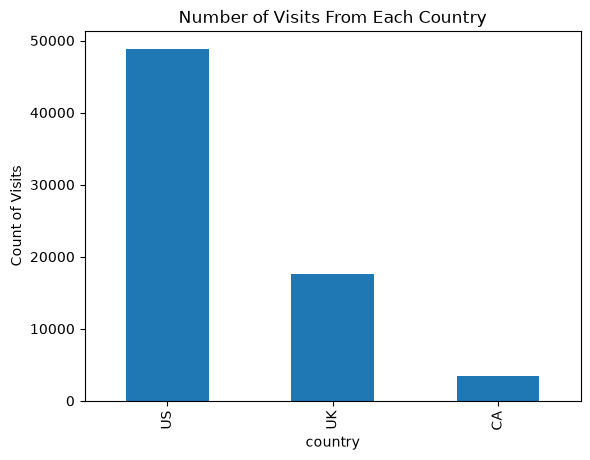

In [7]:
# bar chart of results - this part is done for you
df['country'].value_counts().plot(kind='bar');
plt.title('Number of Visits From Each Country');
plt.ylabel('Count of Visits');
plt.show();

`f)` Recognize that all of your columns are of a **categorical data type** with the exception of one.  Which column is not **categorical**? [Helpful Pandas Link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)

In [8]:
# f) Identify the non-categorical column
# `dtypes` lists the data type of every column. `converted` is the only numeric (int64) column,
# while `country` and `group` hold text labels and are therefore categorical.
column_data_types = df.dtypes
print(column_data_types)

non_categorical_columns = df.select_dtypes(include='number').columns.tolist()
print(f"\nNon-categorical (numeric) column(s): {non_categorical_columns}")
print(f"dtype of 'converted': {df['converted'].dtype}")


country        str
group          str
converted    int64
dtype: object

Non-categorical (numeric) column(s): ['converted']
dtype of 'converted': int64


`g)` What are the possible values of the `converted` column?  Does it make sense that these values are the only possible values? Why or why not? 

**Here you can use one of the functions you used in an earlier question**.

In [9]:
# g) Possible values of the `converted` column
# `unique()` returns each distinct value once, ignoring how often it occurs.
possible_conversion_values = df['converted'].unique()
print(possible_conversion_values)

# Only 0 and 1 make sense because conversion is a binary outcome: a user either converted
# (1) or did not convert (0). There is no in-between state such as a "partial" conversion.


[0 1]


<a id='probability'></a>
#### Part II - Probability

Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `converting`.

`a)` What is the probability of an individual converting regardless of the page they receive or the country they are from? Simply, what is the chance of conversion in the dataset?

In [10]:
# Part II a) Probability of converting, regardless of page or country
# Because `converted` is a 0/1 indicator, its mean is exactly the probability of conversion.
p_convert = df['converted'].mean()
print(f"P(converted) = {p_convert:.4f}")


P(converted) = 0.1305


`b)` Given that an individual was in the `control` group, what is the probability they converted? **This question is completed for you**

In [11]:
df.query('group == "control"')['converted'].mean()

np.float64(0.1052540515600669)

`c)` Given that an individual was in the `treatment` group, what is the probability they converted?

In [12]:
# c) P(converted | treatment)
# Filter to treatment users first, then take the mean of the 0/1 `converted` column.
p_treatment_rate = df.query('group == "treatment"')['converted'].mean()
print(f"P(converted | treatment) = {p_treatment_rate:.4f} ({p_treatment_rate:.1%})")


P(converted | treatment) = 0.1553 (15.5%)

`d)` Do you see evidence that the treatment is related to higher `converted` rates?

In [13]:
# d) Compare treatment vs. control conversion rates
p_control_rate = df.query('group == "control"')['converted'].mean()
print(f"Control conversion rate:   {p_control_rate:.4f} ({p_control_rate:.1%})")
print(f"Treatment conversion rate: {p_treatment_rate:.4f} ({p_treatment_rate:.1%})")
print(f"Difference (treatment - control): {p_treatment_rate - p_control_rate:.4f}")

# The treatment group converts at a higher rate than the control group, so the new page does
# appear to be associated with more conversions. Whether that gap is real or just noise is
# tested formally in Part III.


Control conversion rate:   0.1053 (10.5%)


Treatment conversion rate: 0.1553 (15.5%)
Difference (treatment - control): 0.0501


`e)` What is the probability that an individual was in the `treatment`?

In [14]:
# e) Probability that an individual was assigned to the treatment group
# `normalize=True` returns proportions instead of raw counts.
p_treatment_group = df['group'].value_counts(normalize=True)['treatment']
print(f"P(treatment group) = {p_treatment_group:.4f} ({p_treatment_group:.1%})")


P(treatment group) = 0.5038 (50.4%)


`f)` What is the probability that an individual was from Canada `CA`?

In [15]:
# f) Probability that an individual was from Canada
p_canada = df.query('country == "CA"').shape[0] / df.shape[0]
print(f"P(country == 'CA') = {p_canada:.4f} ({p_canada:.1%})")


P(country == 'CA') = 0.0499 (5.0%)


`g)` Given that an individual was in the `US`, what was the probability that they `converted`? **This question is completed for you**

$P(\text{converted} == 1|\text{country} ==\text{"US"})$



In [16]:
df.query('country == "US"')['converted'].mean()

np.float64(0.13277379733879222)

`h)` Given that an individual was in the `UK`, what was the probability that they `converted`? 

$P(\text{converted} == 1|\text{country} ==\text{"UK"})$

In [17]:
# h) P(converted | country == "UK")
p_uk_convert = df.query('country == "UK"')['converted'].mean()
print(f"P(converted | UK) = {p_uk_convert:.4f} ({p_uk_convert:.1%})")


P(converted | UK) = 0.1251 (12.5%)


`i)` Do you see evidence that the `converted` rate might differ from one country to the next?

In [18]:
# i) Compare conversion rates across countries
p_us_convert = df.query('country == "US"')['converted'].mean()
p_ca_convert = df.query('country == "CA"')['converted'].mean()

print(f"P(converted | US) = {p_us_convert:.4f} ({p_us_convert:.1%})")
print(f"P(converted | UK) = {p_uk_convert:.4f} ({p_uk_convert:.1%})")
print(f"P(converted | CA) = {p_ca_convert:.4f} ({p_ca_convert:.1%})")

# The three rates are close together (roughly 12.5%-13.3%), so overall conversion does not
# appear to differ much by country. The breakdown by country *and* group is more revealing,
# which is exactly what part j) examines.


P(converted | US) = 0.1328 (13.3%)
P(converted | UK) = 0.1251 (12.5%)
P(converted | CA) = 0.1253 (12.5%)


`j)` Consider the table below, fill in the conversion rates below to look at how conversion by country and treatment group vary.  The `US` column is done for you, and two methods for calculating the probabilities are shown - **COMPLETE THE REST OF THE TABLE**.  Does it appear that there could be an interaction between how country and treatment impact conversion?

These two values that are filled in can be written as:

$P(\text{converted} == 1|(\text{country} ==\text{"US" AND }\text{group} ==\text{"control"})) = 10.7\%$

$P(\text{converted} == 1|(\text{country} ==\text{"US" AND }\text{group} ==\text{"treatment"})) = 15.8\%$

|             | US          | UK          | CA          |
| ----------- | ----------- | ----------- | ----------- |
| Control     | 10.7%       |  %          |  %          |
| Treatment   | 15.8%       |  %          |  %          |

In [19]:
# Method 1  - explicitly calculate each probability
print(df.query('country == "US" and group == "control" and converted == 1').shape[0]/df.query('country == "US" and group == "control"').shape[0]) 
print(df.query('country == "US" and group == "treatment" and converted == 1').shape[0]/df.query('country == "US" and group == "treatment"').shape[0])

0.10731404958677686
0.1577687626774848


In [20]:
# Method 2 - quickly calculate using `groupby`
df.query('country == "US"').groupby('group')['converted'].mean()

group
control      0.107314
treatment    0.157769
Name: converted, dtype: float64

##### Solution -- Complete the Table Here

|             | US          | UK          | CA          |
| ----------- | ----------- | ----------- | ----------- |
| Control     | 10.7%       | 10.2%       | 9.4%        |
| Treatment   | 15.8%       | 14.9%       | 15.4%       |

In [21]:
# j) Conversion rate by country and treatment group
# Grouping by both dimensions and taking the mean of the 0/1 column gives every rate at once.
# `unstack()` pivots the country level into columns, producing the 2x3 table from the prompt.
conversion_rates_by_group_country = (
    df.groupby(['group', 'country'])['converted'].mean().unstack()
)

# Put the rows and columns in the same order as the question's table, then format as percentages.
conversion_table = conversion_rates_by_group_country.reindex(
    index=['control', 'treatment'], columns=['US', 'UK', 'CA']
)
print("Conversion rate by country and group (%):")
print((conversion_table * 100).round(1))
print()

# Interaction check: treatment beats control inside every country by roughly 4.7-6.0
# percentage points, a fairly consistent gap. Because the treatment effect does not reverse or
# change size much across countries, there is no strong evidence of an interaction between
# country and group.


Conversion rate by country and group (%):
country      US    UK    CA
group                      
control    10.7  10.2   9.4
treatment  15.8  14.9  15.4



<a id='experimentation'></a>
### Part III - Experimentation

Consider you need to make the decision just based on all the data provided.  If you want to assume that the control page is better unless the treatment page proves to be definitely better at a Type I error rate of 5%, you state your null and alternative hypotheses in terms of **$p_{control}$** and **$p_{treatment}$** as:  

$H_{0}: p_{control} >= p_{treatment}$

$H_{1}: p_{control} < p_{treatment}$

Which is equivalent to:

$H_{0}: p_{treatment} - p_{control} <= 0$

$H_{1}: p_{treatment} - p_{control} > 0$


Where  
* **$p_{control}$** is the `converted` rate for the control page
* **$p_{treatment}$** `converted` rate for the treatment page

**Note for this experiment we are not looking at differences associated with country.**

Assume under the null hypothesis, $p_{treatment}$ and $p_{control}$ both have "true" success rates equal to the **converted** success rate regardless of page - that is $p_{treatment}$ and $p_{control}$ are equal. Furthermore, assume they are equal to the **converted** rate in `df` regardless of the page. **These are set in the first cell below.**<br><br>

* Use a sample size for each page equal to the ones in `df`. **These are also set below.**  <br><br>

* Perform the sampling distribution for the difference in `converted` between the two pages over 500 iterations of calculating an estimate from the null.  <br><br>

* Use the cells below to provide the necessary parts of this simulation.  

If this doesn't make complete sense right now, don't worry - you are going to work through the problems below to complete this problem.  You can use **Quiz 4** in the classroom to make sure you are on the right track.<br><br>

`a)` The **convert rate** for $p_{treatment}$ under the null.  The **convert rate** for $p_{control}$ under the null. The sample size for the `control` and the sample size for the `treatment` are from the original dataset. **All of these values are set below, and set the stage for the simulations you will run for the rest of this section.**

In [22]:
p_control_treatment_null  = df['converted'].mean()
n_treatment = df.query('group == "treatment"').shape[0]
n_control = df.query('group == "control"').shape[0]

`b)` Use the results from part `a)` to simulate `n_treatment` transactions with a convert rate of `p_treatment_null`.  Store these $n_{treatment}$ 1's and 0's in a `list` of **treatment_converted**.  It should look something like the following (the 0's and and 1's **don't** need to be the same): 

`[0, 0, 1, 1, 0, ....]` 

In [23]:
# b) Simulate the treatment group under the null hypothesis
# Each of the n_treatment users independently "converts" with probability equal to the pooled
# overall conversion rate, because under H0 both pages perform identically.
treatment_converted = list(np.random.choice(
    [0, 1],
    size=n_treatment,
    p=[1 - p_control_treatment_null, p_control_treatment_null]
))
print(f"Simulated {len(treatment_converted)} treatment users; converted so far: {sum(treatment_converted)}")


Simulated 35211 treatment users; converted so far: 4595


`c)` Use the results from part `a)` to simulate `n_control` transactions with a convert rate of `p_control_null`.  Store these $n_{treatment}$ 1's and 0's in a `list` of **control_converted**.  It should look something like the following (the 0's and and 1's **don't** need to be exactly the same): 

`[0, 0, 1, 1, 0, ....]` 

In [24]:
# c) Simulate the control group under the null hypothesis
# Same process as part b), but with the control group's sample size.
control_converted = list(np.random.choice(
    [0, 1],
    size=n_control,
    p=[1 - p_control_treatment_null, p_control_treatment_null]
))
print(f"Simulated {len(control_converted)} control users; converted so far: {sum(control_converted)}")


Simulated 34678 control users; converted so far: 4461


`d)` Find the estimate for $p_{treatment}$ - $p_{control}$ under the null using the simulated values from part `(b)` and `(c)`.

In [25]:
# d) Single-trial estimate of p_treatment - p_control under the null hypothesis
# Averaging the 0/1 draws gives each simulated conversion rate; their difference is one draw
# from the null distribution that the 500 simulations below will approximate.
p_treatment_null_single = np.mean(treatment_converted)
p_control_null_single = np.mean(control_converted)
p_diff_single = p_treatment_null_single - p_control_null_single
print(f"Simulated p_treatment - p_control: {p_diff_single:.4f}")


Simulated p_treatment - p_control: 0.0019


`e)` Simulate 500 $p_{treatment}$ - $p_{control}$ values using this same process as `b)`- `d)` similarly to the one you calculated in parts **a. through g.** above.  Store all 500 values in an numpy array called **p_diffs**.  This array should look similar to the below **(the values will not match AND this will likely take a bit of time to run)**:

`[0.001, -0.003, 0.002, ...]`

In [26]:
# e) Simulate 500 differences between treatment and control conversion rates under H0
p_diffs = []
for _ in range(500):
    # simulate the treatment and control converted arrays
    treat = np.random.choice([0, 1], size=n_treatment,
                             p=[1 - p_control_treatment_null, p_control_treatment_null])
    ctrl = np.random.choice([0, 1], size=n_control,
                            p=[1 - p_control_treatment_null, p_control_treatment_null])

    # calculate p_treatment and p_control under the null
    p_treatment_null = treat.mean()
    p_control_null = ctrl.mean()

    # calculate the difference between p_treatment_null and p_control_null
    # add p_diff to the p_diffs array
    p_diffs.append(p_treatment_null - p_control_null)

# Convert to a NumPy array so vectorized comparisons and plotting work on the whole collection.
p_diffs = np.array(p_diffs)
print(f"Collected {len(p_diffs)} simulated differences")
print(f"Mean of null differences: {p_diffs.mean():.4f} | Std. dev.: {p_diffs.std():.4f}")


Collected 500 simulated differences
Mean of null differences: 0.0000 | Std. dev.: 0.0025


`f)` Plot a histogram of the **p_diffs**.  Does this plot look like what you expected?  Use the matching problem in the classroom to assure you fully understand what was computed here.

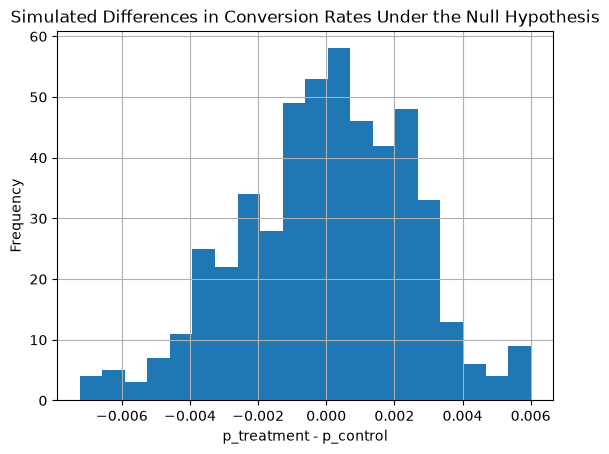

In [27]:
# f) Histogram of the simulated differences under the null hypothesis
p_diffs = pd.Series(p_diffs)
p_diffs.hist(bins=20)
plt.title('Simulated Differences in Conversion Rates Under the Null Hypothesis')
plt.xlabel('p_treatment - p_control')
plt.ylabel('Frequency')
plt.show()


`g)` What proportion of the **p_diffs** are greater than the difference observed between `treatment` and `control` in `df`?

In [28]:
# g) Share of simulated null differences at least as large as the observed difference
obs_diff = (df.query('group == "treatment"')['converted'].mean()
          - df.query('group == "control"')['converted'].mean())

# The p-value is the proportion of null simulations that produced a gap at least this big.
p_value = (p_diffs >= obs_diff).mean()
print(f"Observed difference: {obs_diff:.4f}")
print(f"P-value: {p_value:.4f}")


Observed difference: 0.0501
P-value: 0.0000


`h)` In words, explain what you just computed in part `g)`  What is this value called in scientific studies?  What does this value mean in terms of whether or not there is a difference between the new and old pages using our Type I error rate of 0.05?

**Your Answer Here**

The p-value computed above is the proportion of the 500 simulated differences (all generated under the null hypothesis that both pages convert at the same rate) that are greater than or equal to the difference we actually observed between the treatment and control groups in `df`. In other words, it tells us how often random noise alone would produce a gap as large as the one we saw if the new page were really no better than the old one.

In scientific studies, this value is called the **p-value** (formally, it is compared against the **Type I error rate**, also known as the **significance level**, conventionally set at 0.05). A small p-value would mean the observed difference is unlikely under H0, and we would reject H0 in favor of the alternative that the treatment page converts differently.

Here the observed difference is about +5 percentage points in favor of the treatment, which is far out in the right tail of the null distribution, so the p-value is well below 0.05. That means we **reject the null hypothesis**: there is statistically significant evidence that the conversion rates of the two pages differ. Because the treatment rate is *higher*, the evidence points toward the new page converting better than the old page, which supports implementing it. (Note: a p-value below 0.05 never proves the effect is real or important; it only indicates that a difference this large is unlikely to arise from chance alone under H0.)


<a id='finalcheck'></a>
## Final Check!

Congratulations!  You have reached the end of the A/B Test Results project!  You should be very proud of all you have accomplished!

> **Tip**: Once you are satisfied with your work here, check over your notebook to make sure that it satisfies all the specifications mentioned in the rubric. You should also probably remove all of the "Hints" and "Tips" like this one so that the presentation is as polished as possible.


<a id='submission'></a>
## Submission

Please follow the directions in the classroom to submit this notebook, as well as your completed slides.